# Analisis COVID-19 dan Mobilitas Masyarakat Indonesia

Proyek kelompok (3 orang), mata kuliah Data Analysis, Universitas Multimedia Nusantara (2025).


## Memuat Dataset



In [28]:
import pandas as pd

df_covid = pd.read_csv('data/covid_19_indonesia_time_series_all.csv')
df_mobility_2020 = pd.read_csv('data/2020_ID_Region_Mobility_Report.csv')
df_mobility_2021 = pd.read_csv('data/2021_ID_Region_Mobility_Report.csv')

print("First 5 rows of df_covid:")
print(df_covid.head())
print("\nFirst 5 rows of df_mobility_2020:")
print(df_mobility_2020.head())
print("\nFirst 5 rows of df_mobility_2021:")
print(df_mobility_2021.head())

First 5 rows of df_covid:
       Date Location ISO Code     Location  New Cases  New Deaths  \
0  3/1/2020             ID-JK  DKI Jakarta          2           0   
1  3/2/2020             ID-JK  DKI Jakarta          2           0   
2  3/2/2020               IDN    Indonesia          2           0   
3  3/2/2020             ID-RI         Riau          1           0   
4  3/3/2020             ID-JK  DKI Jakarta          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2           39            20   
1              0                 2           41            20   
2              0                 2            2             0   
3              0                 1            1             0   
4              0                 2           43            20   

   Total Recovered  ...  Latitude New Cases per Million  \
0               75  ... -6.204699                  0.18   
1               75  ... -6.204699                 

## Pemahaman Data Awal




In [29]:
print("\n--- df_covid Info ---")
df_covid.info()
print("\n--- df_covid Describe ---")
print(df_covid.describe())
print("\n--- df_covid Missing Values ---")
print(df_covid.isnull().sum())

print("\n--- df_mobility_2020 Info ---")
df_mobility_2020.info()
print("\n--- df_mobility_2020 Describe ---")
print(df_mobility_2020.describe())
print("\n--- df_mobility_2020 Missing Values ---")
print(df_mobility_2020.isnull().sum())

print("\n--- df_mobility_2021 Info ---")
df_mobility_2021.info()
print("\n--- df_mobility_2021 Describe ---")
print(df_mobility_2021.describe())
print("\n--- df_mobility_2021 Missing Values ---")
print(df_mobility_2021.isnull().sum())


--- df_covid Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31822 entries, 0 to 31821
Data columns (total 38 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Date                         31822 non-null  object 
 1   Location ISO Code            31822 non-null  object 
 2   Location                     31822 non-null  object 
 3   New Cases                    31822 non-null  int64  
 4   New Deaths                   31822 non-null  int64  
 5   New Recovered                31822 non-null  int64  
 6   New Active Cases             31822 non-null  int64  
 7   Total Cases                  31822 non-null  int64  
 8   Total Deaths                 31822 non-null  int64  
 9   Total Recovered              31822 non-null  int64  
 10  Total Active Cases           31822 non-null  int64  
 11  Location Level               31822 non-null  object 
 12  City or Regency              0 non-null      float6

## Pembersihan & Integrasi Data




In [30]:
import numpy as np

# 1. Konversi kolom tanggal ke tipe data datetime
df_covid['Date'] = pd.to_datetime(df_covid['Date'])
df_mobility_2020['date'] = pd.to_datetime(df_mobility_2020['date'])
df_mobility_2021['date'] = pd.to_datetime(df_mobility_2021['date'])

# 2. Ganti nama kolom 'Date' di df_covid menjadi 'date'
df_covid = df_covid.rename(columns={'Date': 'date'})




In [31]:
# 3. Hapus kolom 'sub_region_2', 'metro_area', dan 'census_fips_code'
columns_to_drop_mobility = ['sub_region_2', 'metro_area', 'census_fips_code']
df_mobility_2020 = df_mobility_2020.drop(columns=columns_to_drop_mobility, errors='ignore')
df_mobility_2021 = df_mobility_2021.drop(columns=columns_to_drop_mobility, errors='ignore')

# 4. Isi nilai yang hilang dalam kolom persentase perubahan mobilitas dengan 0
mobility_percentage_cols = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]
for col in mobility_percentage_cols:
    if col in df_mobility_2020.columns:
        df_mobility_2020[col] = df_mobility_2020[col].fillna(0)
    if col in df_mobility_2021.columns:
        df_mobility_2021[col] = df_mobility_2021[col].fillna(0)

In [32]:
# 5. Gabungkan df_mobility_2020 dan df_mobility_2021
df_mobility = pd.concat([df_mobility_2020, df_mobility_2021], ignore_index=True)

# 6. Filter df_covid untuk data nasional ('Location' adalah 'Indonesia')
df_covid_national = df_covid[df_covid['Location'] == 'Indonesia'].copy()

In [33]:
# 7. Filter df_mobility untuk data mobilitas tingkat nasional ('sub_region_1' bernilai null)
df_mobility_national = df_mobility[df_mobility['sub_region_1'].isnull()].copy()

# 8. Hapus kolom 'City or Regency' dan 'Special Status' dari df_covid_national
columns_to_drop_covid = ['City or Regency', 'Special Status']
df_covid_national = df_covid_national.drop(columns=columns_to_drop_covid, errors='ignore')

In [34]:
# 10. Pastikan nilai di kolom 'New Active Cases' dan 'Total Active Cases' tidak negatif
df_covid_national['New Active Cases'] = df_covid_national['New Active Cases'].apply(lambda x: max(x, 0))
df_covid_national['Total Active Cases'] = df_covid_national['Total Active Cases'].apply(lambda x: max(x, 0))

In [35]:
# 11. Isi nilai yang hilang di kolom 'Growth Factor' dengan 1
df_covid_national['Growth Factor of New Cases'] = df_covid_national['Growth Factor of New Cases'].fillna(1)
df_covid_national['Growth Factor of New Deaths'] = df_covid_national['Growth Factor of New Deaths'].fillna(1)

# 12. Gabungkan df_covid_national dengan df_mobility_national berdasarkan kolom 'date'
df_merged = pd.merge(df_covid_national, df_mobility_national, on='date', how='inner')

In [36]:
# 13. Tampilkan lima baris pertama (.head()) dan informasi (.info()) dari df_merged
print("\n--- First 5 rows of df_merged ---")
print(df_merged.head())
print("\n--- Info of df_merged ---")
df_merged.info()


--- First 5 rows of df_merged ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  country_region sub_region_1 iso_3166_2_code  \
0                0  ...       Indonesia          NaN             NaN   
1                0  .

## Analisis Data Eksploratif (EDA)




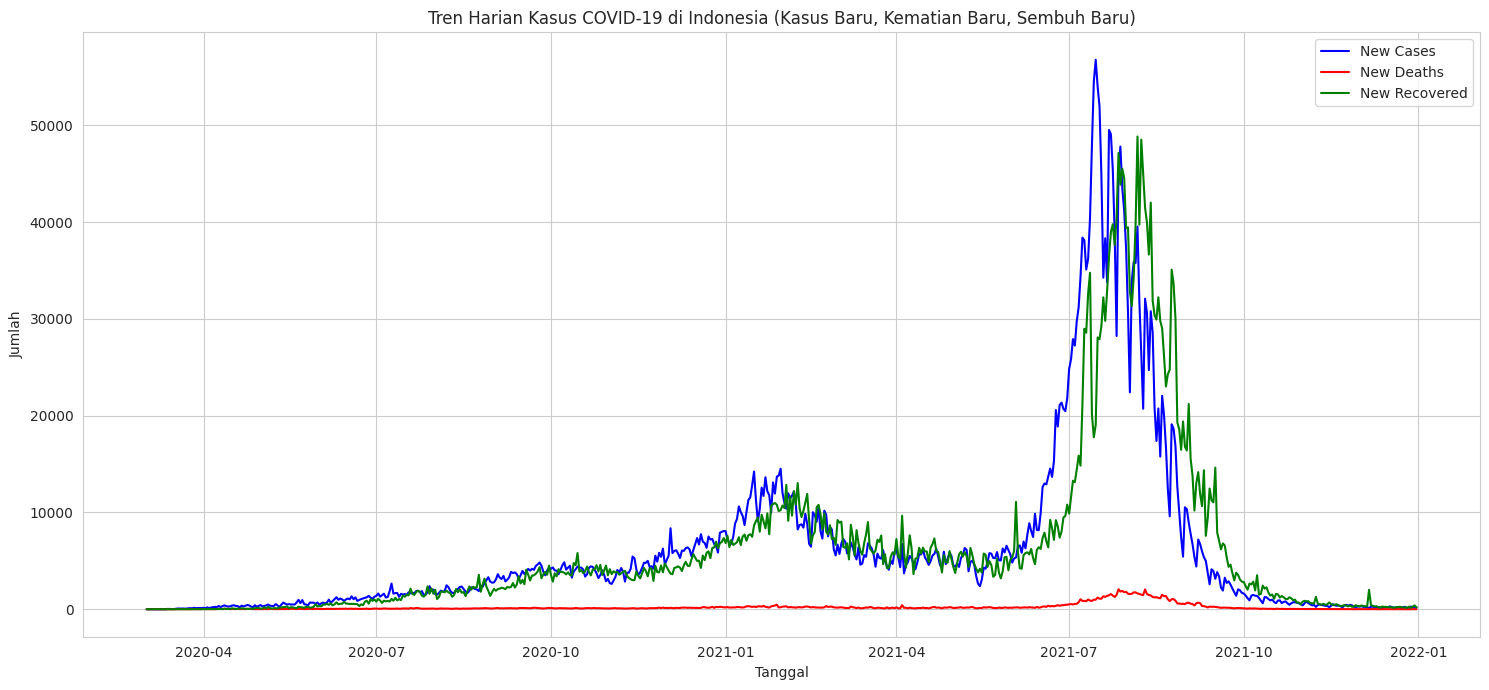

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_style("whitegrid")

# 1. Plot time series for 'New Cases', 'New Deaths', and 'New Recovered'
plt.figure(figsize=(15, 7))
plt.plot(df_merged['date'], df_merged['New Cases'], label='New Cases', color='blue')
plt.plot(df_merged['date'], df_merged['New Deaths'], label='New Deaths', color='red')
plt.plot(df_merged['date'], df_merged['New Recovered'], label='New Recovered', color='green')
plt.title('Tren Harian Kasus COVID-19 di Indonesia (Kasus Baru, Kematian Baru, Sembuh Baru)')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


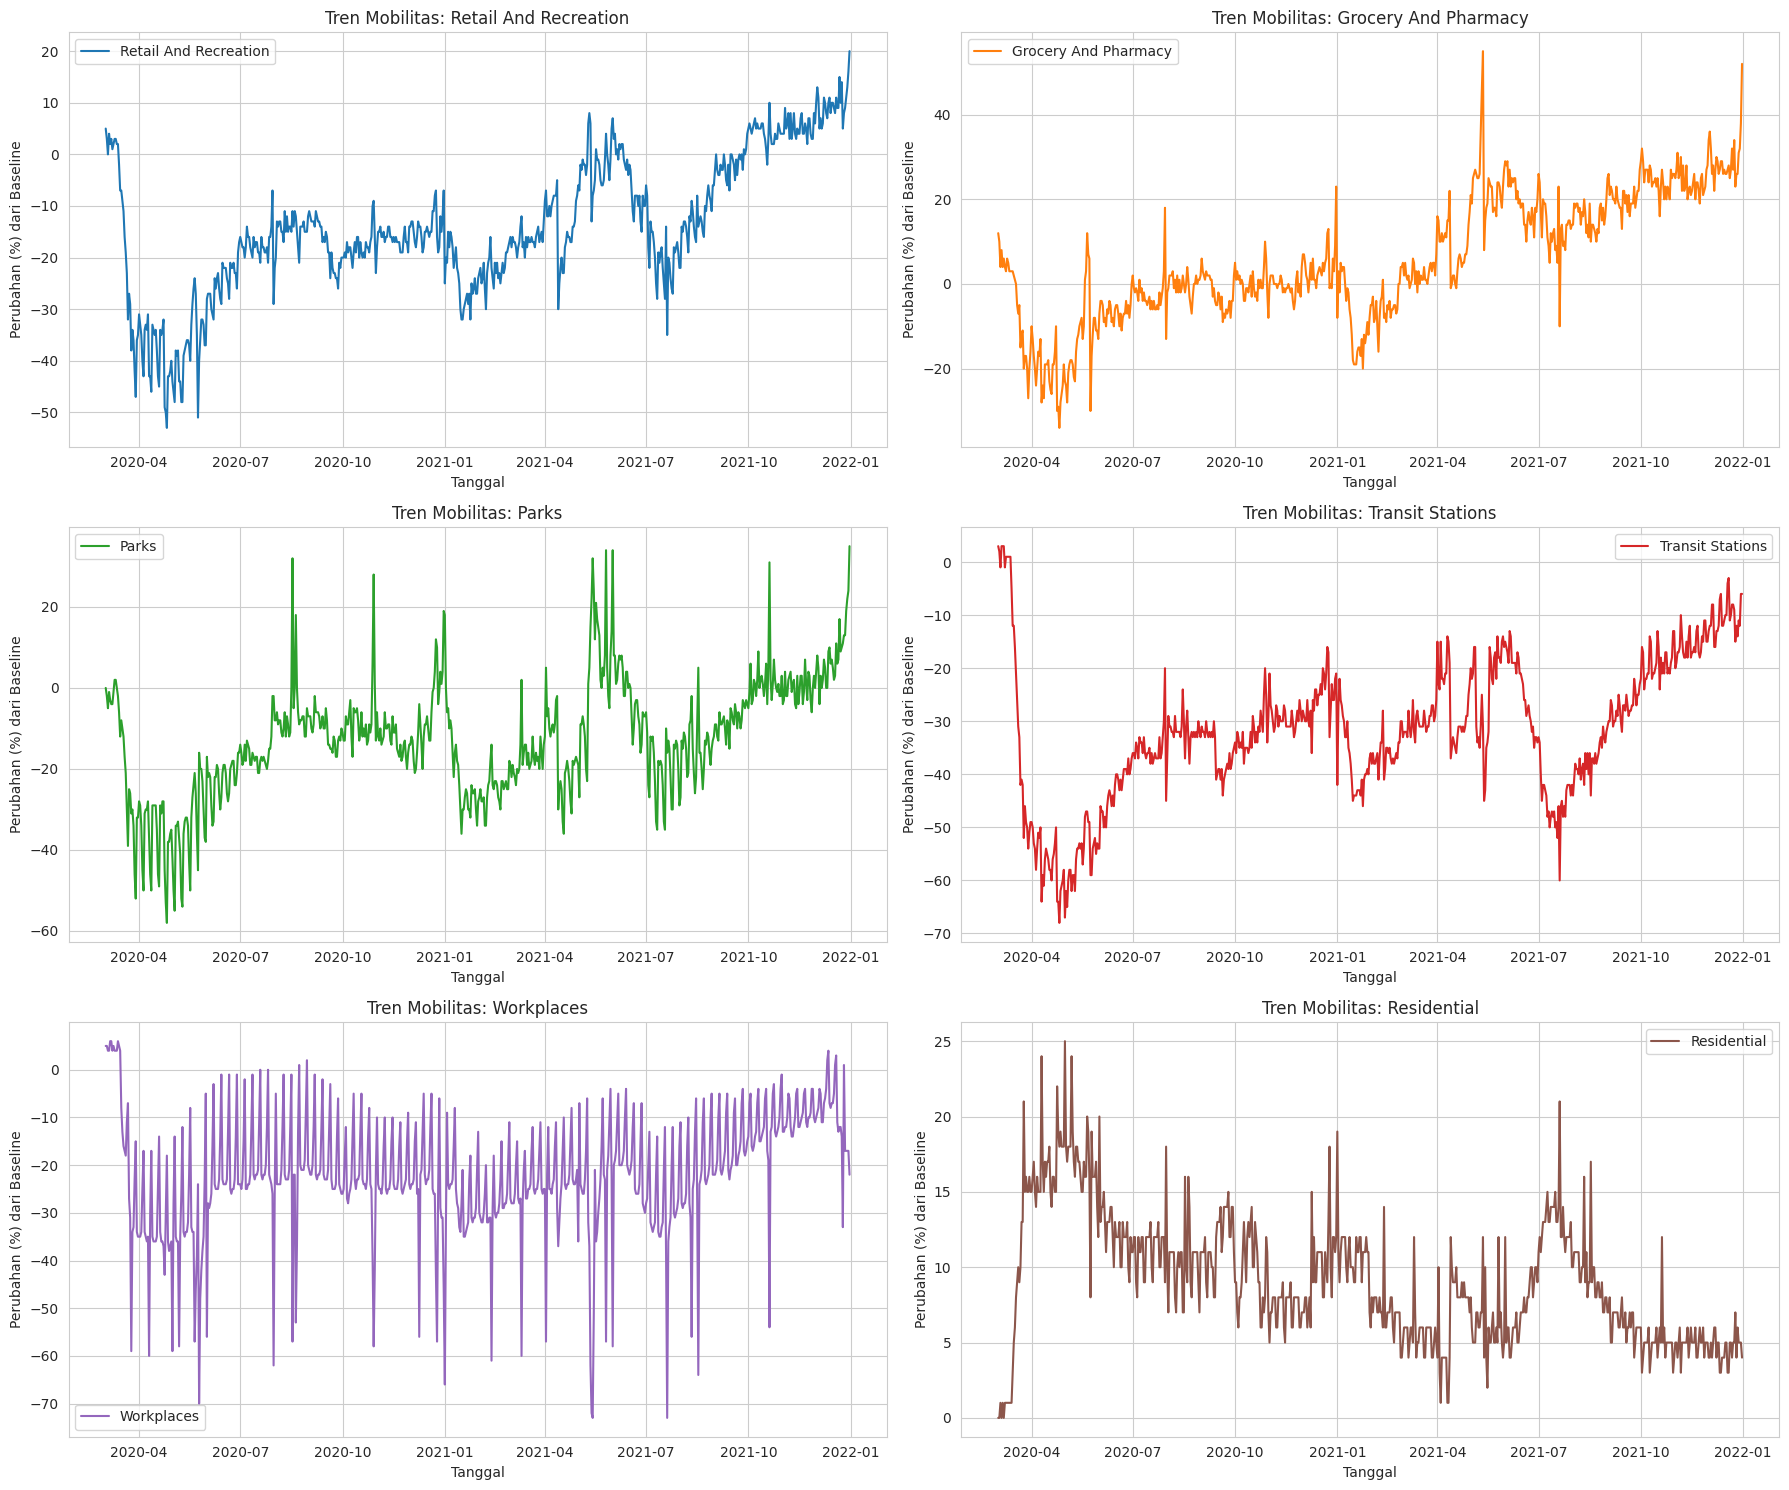

In [38]:
mobility_cols = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]

# 2. Plot time series for each mobility percentage change column
plt.figure(figsize=(18, 15))
for i, col in enumerate(mobility_cols):
    plt.subplot(3, 2, i + 1) # 3 rows, 2 columns of subplots
    plt.plot(df_merged['date'], df_merged[col], label=col.replace('_percent_change_from_baseline', '').replace('_', ' ').title(), color=sns.color_palette('tab10')[i])
    plt.title(f'Tren Mobilitas: {col.replace('_percent_change_from_baseline', '').replace('_', ' ').title()}')
    plt.xlabel('Tanggal')
    plt.ylabel('Perubahan (%) dari Baseline')
    plt.grid(True)
    plt.legend()
plt.tight_layout()
plt.show()

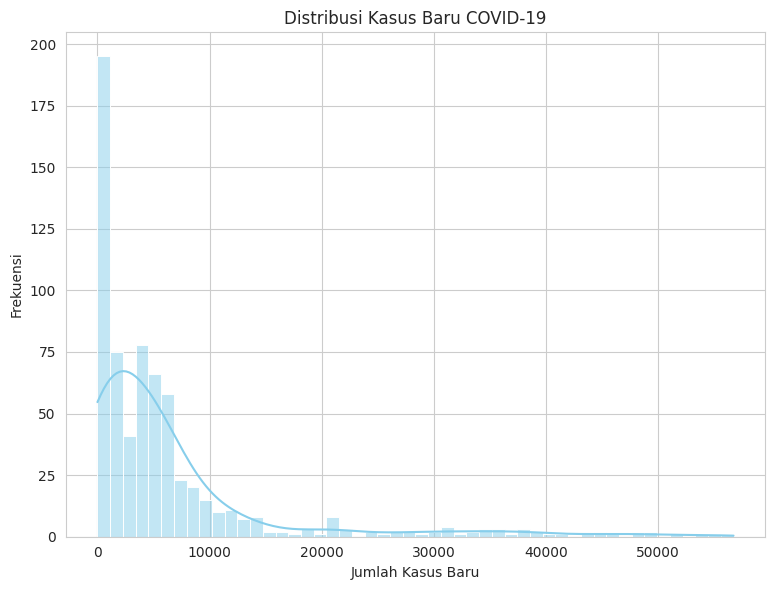

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(15, 6))

# Histogram for New Cases
plt.subplot(1, 2, 1)
sns.histplot(df_merged['New Cases'], kde=True, bins=50, color='skyblue')
plt.title('Distribusi Kasus Baru COVID-19')
plt.xlabel('Jumlah Kasus Baru')
plt.ylabel('Frekuensi')


plt.tight_layout()
plt.show()

In [40]:
mobility_cols = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]

# Select relevant columns for correlation calculation
correlation_cols = ['New Cases'] + mobility_cols

# Calculate the correlation matrix
correlation_matrix = df_merged[correlation_cols].corr()

# Display the correlation matrix
print("Matriks Korelasi antara Kasus Baru COVID-19 dan Metrik Mobilitas:")
print(correlation_matrix)

Matriks Korelasi antara Kasus Baru COVID-19 dan Metrik Mobilitas:
                                                    New Cases  \
New Cases                                            1.000000   
retail_and_recreation_percent_change_from_baseline  -0.103893   
grocery_and_pharmacy_percent_change_from_baseline    0.138236   
parks_percent_change_from_baseline                  -0.126768   
transit_stations_percent_change_from_baseline       -0.237574   
workplaces_percent_change_from_baseline             -0.187885   
residential_percent_change_from_baseline             0.150040   

                                                    retail_and_recreation_percent_change_from_baseline  \
New Cases                                                                                   -0.103893    
retail_and_recreation_percent_change_from_baseline                                           1.000000    
grocery_and_pharmacy_percent_change_from_baseline                                            0.

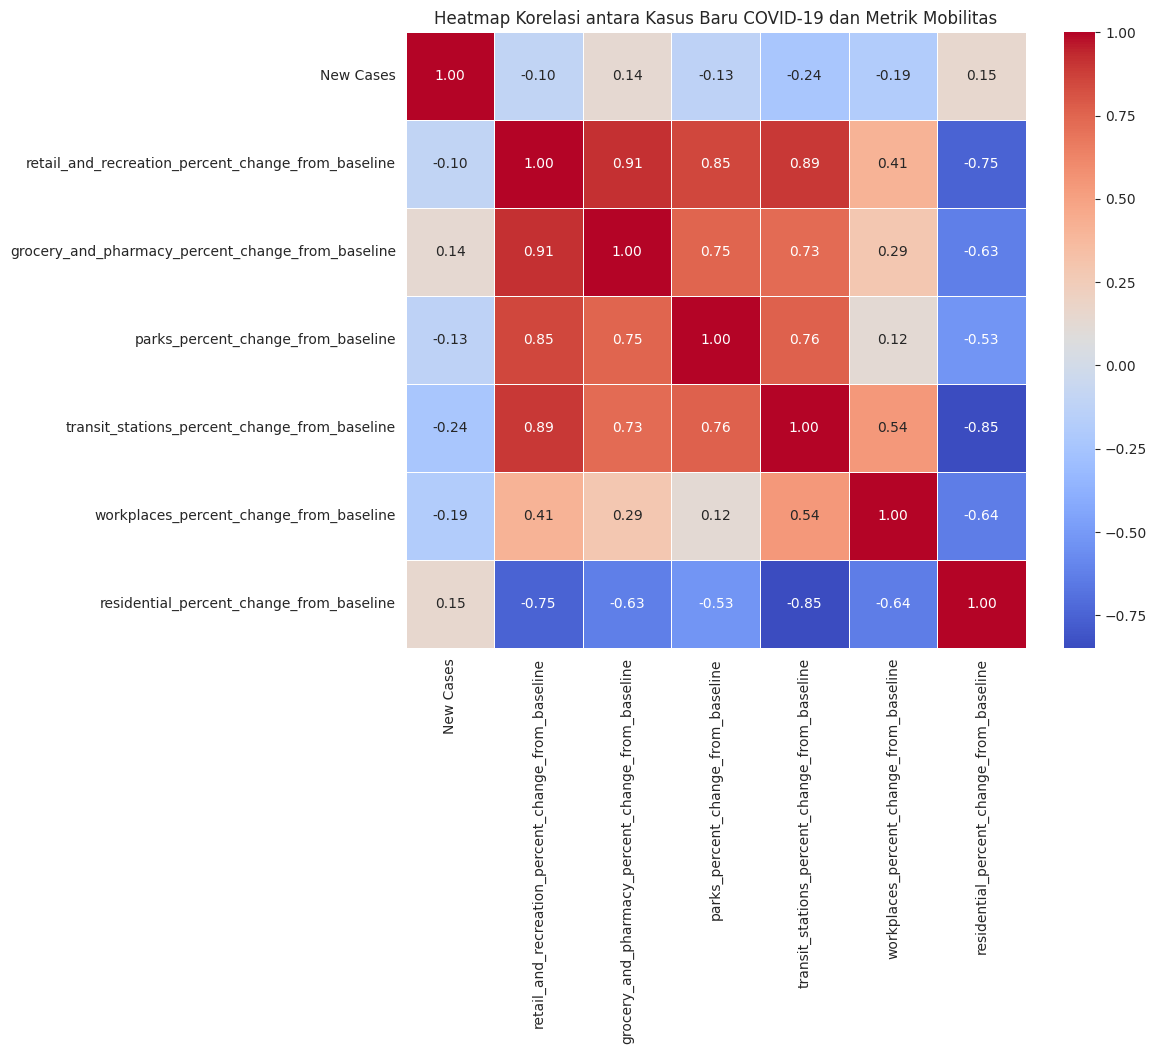

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap Korelasi antara Kasus Baru COVID-19 dan Metrik Mobilitas')
plt.show()

## Feature Engineering




In [42]:
lag_periods = [1, 3, 7, 14]
cases_cols = ['New Cases']
mobility_cols = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]

In [43]:
# 1. Create lag features for 'New Cases'
for col in cases_cols:
    for lag in lag_periods:
        df_merged[f'{col}_lag_{lag}'] = df_merged[col].shift(lag).fillna(0)


print("--- First 5 rows of df_merged with new features ---")
print(df_merged.head())

--- First 5 rows of df_merged with new features ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  retail_and_recreation_percent_change_from_baseline  \
0                0  ...                                              

In [44]:
# 2. Create lag features for mobility columns
for m_col in mobility_cols:
    for lag in lag_periods:
        df_merged[f'{m_col}_lag_{lag}'] = df_merged[m_col].shift(lag).fillna(0)

print("--- First 5 rows of df_merged with new features ---")
print(df_merged.head())

--- First 5 rows of df_merged with new features ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  transit_stations_percent_change_from_baseline_lag_7  \
0                0  ...                                             

In [45]:
# 3. Calculate 7-day rolling mean for 'New Cases' and mobility columns
for col in cases_cols + mobility_cols:
    df_merged[f'{col}_rolling_mean_7'] = df_merged[col].rolling(window=7).mean().fillna(0)

print("--- First 5 rows of df_merged with new features ---")
print(df_merged.head())

--- First 5 rows of df_merged with new features ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  residential_percent_change_from_baseline_lag_3  \
0                0  ...                                             0.0  

In [46]:
# 4. Extract month and year from 'date' column
df_merged['month'] = df_merged['date'].dt.month
df_merged['year'] = df_merged['date'].dt.year

print("--- First 5 rows of df_merged with new features ---")
print(df_merged.head())

--- First 5 rows of df_merged with new features ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  residential_percent_change_from_baseline_lag_14  \
0                0  ...                                              0.0

In [47]:
# 5. Create binary 'is_ppkm' feature
ppkm_start = pd.to_datetime('2021-07-03')
ppkm_end = pd.to_datetime('2021-08-09')
df_merged['is_ppkm'] = ((df_merged['date'] >= ppkm_start) & (df_merged['date'] <= ppkm_end)).astype(int)

print("--- First 5 rows of df_merged with new features ---")
print(df_merged.head())

--- First 5 rows of df_merged with new features ---
        date Location ISO Code   Location  New Cases  New Deaths  \
0 2020-03-02               IDN  Indonesia          2           0   
1 2020-03-03               IDN  Indonesia          0           0   
2 2020-03-04               IDN  Indonesia          0           0   
3 2020-03-05               IDN  Indonesia          0           0   
4 2020-03-06               IDN  Indonesia          2           0   

   New Recovered  New Active Cases  Total Cases  Total Deaths  \
0              0                 2            2             0   
1              0                 0            2             0   
2              0                 0            2             0   
3              0                 0            2             0   
4              0                 2            4             0   

   Total Recovered  ...  New Cases_rolling_mean_7  \
0                0  ...                       0.0   
1                0  ...                   

/tmp/ipython-input-2463559677.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='month', y='New Cases', data=avg_new_cases_per_month, palette='viridis')


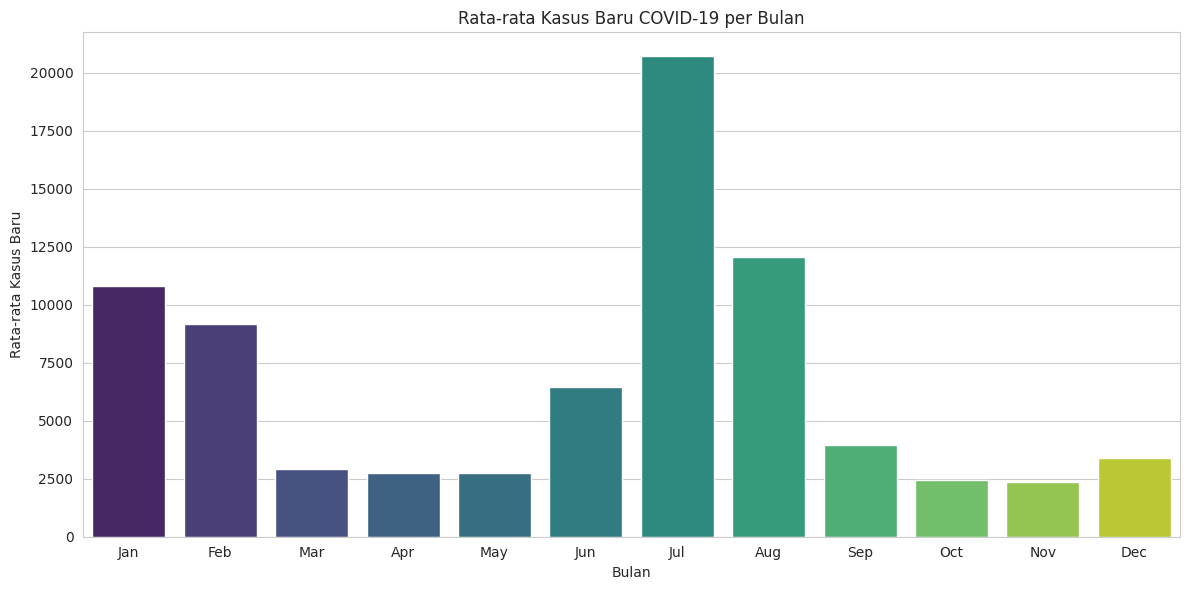

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Calculate average new cases per month
avg_new_cases_per_month = df_merged.groupby('month')['New Cases'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(x='month', y='New Cases', data=avg_new_cases_per_month, palette='viridis')
plt.title('Rata-rata Kasus Baru COVID-19 per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata Kasus Baru')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.tight_layout()
plt.show()

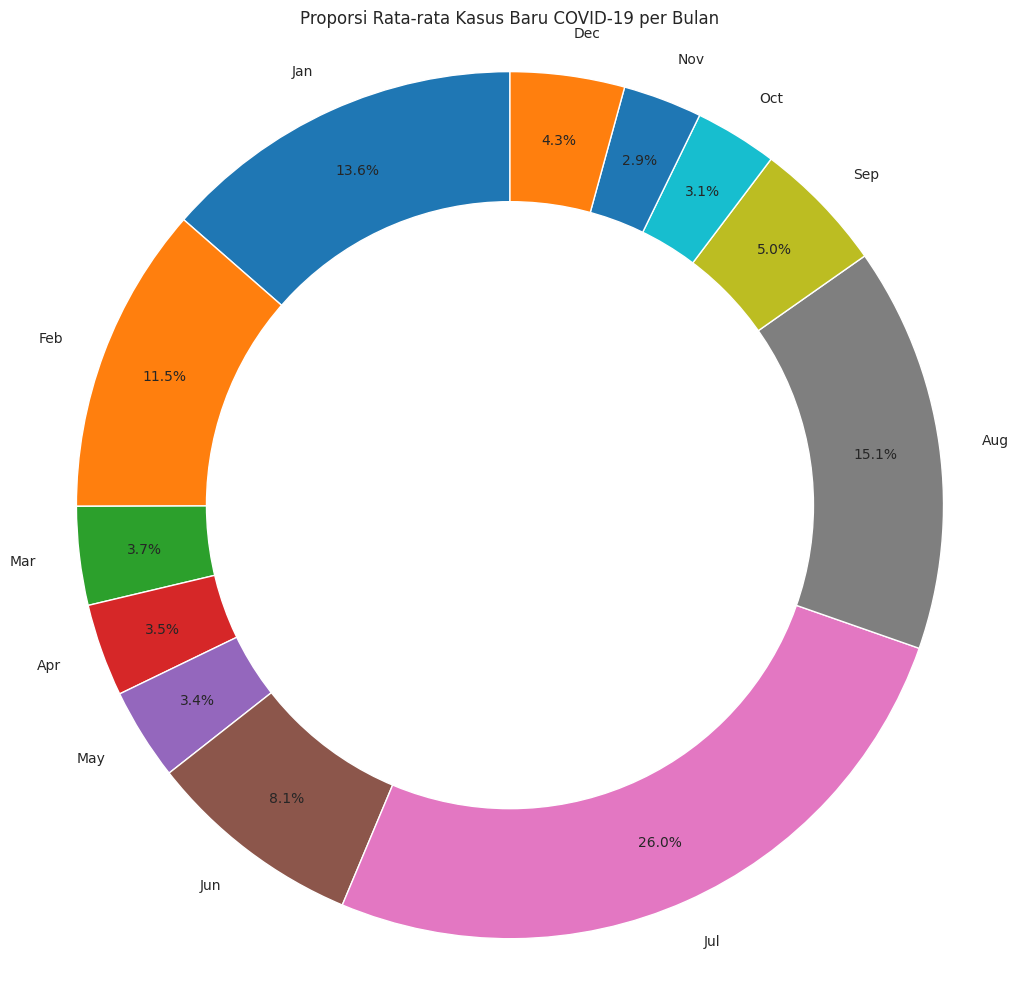

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Create a Donut chart
plt.figure(figsize=(10, 10))
plt.pie(
    avg_new_cases_per_month['New Cases'],
    labels=avg_new_cases_per_month['month'].map({1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}),
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.85
)

# Add a circle at the center to make it a donut chart
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Proporsi Rata-rata Kasus Baru COVID-19 per Bulan')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()

## Persiapan Data untuk Pemodelan




In [50]:
import numpy as np

# 1. Tentukan variabel target
target = 'New Cases'

# 2. Tentukan daftar fitur yang akan digunakan
features = [
    'New Cases_lag_1',
    'New Cases_lag_3',
    'New Cases_lag_7',
    'New Cases_lag_14',
    'New Cases_rolling_mean_7',
    'month',
    'year',
    'is_ppkm'
]

mobility_metrics = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]

# Add current mobility metrics and their lagged/rolling mean versions to features
for col in mobility_metrics:
    features.append(col)
    for lag in [1, 3, 7, 14]: # Assuming these lags are relevant for mobility as well
        features.append(f'{col}_lag_{lag}')
    features.append(f'{col}_rolling_mean_7')

final_features = [f for f in features if f in df_merged.columns]

# 3. Bagi dataset menjadi set pelatihan dan pengujian (80% pelatihan, 20% pengujian) secara kronologis
split_index = int(len(df_merged) * 0.8)

df_train = df_merged.iloc[:split_index]
df_test = df_merged.iloc[split_index:]

print(f"Ukuran data pelatihan: {len(df_train)} baris")
print(f"Ukuran data pengujian: {len(df_test)} baris")

# 4. Pisahkan fitur (X) dan target (y) untuk set pelatihan dan pengujian
X_train = df_train[final_features]
y_train = df_train[target]
X_test = df_test[final_features]
y_test = df_test[target]

print("\nBentuk X_train:", X_train.shape)
print("Bentuk y_train:", y_train.shape)
print("Bentuk X_test:", X_test.shape)
print("Bentuk y_test:", y_test.shape)

print("\nFitur yang digunakan:", final_features)
print("Target variabel:", target)

Ukuran data pelatihan: 536 baris
Ukuran data pengujian: 134 baris

Bentuk X_train: (536, 44)
Bentuk y_train: (536,)
Bentuk X_test: (134, 44)
Bentuk y_test: (134,)

Fitur yang digunakan: ['New Cases_lag_1', 'New Cases_lag_3', 'New Cases_lag_7', 'New Cases_lag_14', 'New Cases_rolling_mean_7', 'month', 'year', 'is_ppkm', 'retail_and_recreation_percent_change_from_baseline', 'retail_and_recreation_percent_change_from_baseline_lag_1', 'retail_and_recreation_percent_change_from_baseline_lag_3', 'retail_and_recreation_percent_change_from_baseline_lag_7', 'retail_and_recreation_percent_change_from_baseline_lag_14', 'retail_and_recreation_percent_change_from_baseline_rolling_mean_7', 'grocery_and_pharmacy_percent_change_from_baseline', 'grocery_and_pharmacy_percent_change_from_baseline_lag_1', 'grocery_and_pharmacy_percent_change_from_baseline_lag_3', 'grocery_and_pharmacy_percent_change_from_baseline_lag_7', 'grocery_and_pharmacy_percent_change_from_baseline_lag_14', 'grocery_and_pharmacy_perc

## Random Forest Regression




In [51]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Inisialisasi model RandomForestRegressor
rf_model = RandomForestRegressor(random_state=42)

# 2. Latih rf_model menggunakan data pelatihan
rf_model.fit(X_train, y_train)

# 3. Buat prediksi pada X_test
y_pred_rf = rf_model.predict(X_test)

# 4. Hitung metrik evaluasi
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# 5. Cetak nilai-nilai metrik evaluasi
print(f"Random Forest Regressor Performance:")
print(f"  RMSE: {rmse_rf:.2f}")
print(f"  MAE: {mae_rf:.2f}")
print(f"  R-squared: {r2_rf:.2f}")

# Store results for comparison later
rf_results = {
    'RMSE': rmse_rf,
    'MAE': mae_rf,
    'R2': r2_rf
}


Random Forest Regressor Performance:
  RMSE: 1975.46
  MAE: 859.93
  R-squared: 0.77


## XGBoost Regression




In [52]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Inisialisasi model XGBRegressor
xgb_model = XGBRegressor(random_state=42)

# 2. Latih xgb_model menggunakan data pelatihan
xgb_model.fit(X_train, y_train)

# 3. Buat prediksi pada X_test
y_pred_xgb = xgb_model.predict(X_test)

# 4. Hitung metrik evaluasi
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

# 5. Cetak nilai-nilai metrik evaluasi
print(f"XGBoost Regressor Performance:")
print(f"  RMSE: {rmse_xgb:.2f}")
print(f"  MAE: {mae_xgb:.2f}")
print(f"  R-squared: {r2_xgb:.2f}")

# 6. Simpan hasil evaluasi untuk perbandingan nanti
xgb_results = {
    'RMSE': rmse_xgb,
    'MAE': mae_xgb,
    'R2': r2_xgb
}

XGBoost Regressor Performance:
  RMSE: 2069.73
  MAE: 1067.56
  R-squared: 0.75


## Gradient Boosting Regression



In [53]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Inisialisasi model GradientBoostingRegressor
gbr_model = GradientBoostingRegressor(random_state=42)

# 2. Latih gbr_model menggunakan data pelatihan
gbr_model.fit(X_train, y_train)

# 3. Buat prediksi pada X_test
y_pred_gbr = gbr_model.predict(X_test)

# 4. Hitung metrik evaluasi
rmse_gbr = np.sqrt(mean_squared_error(y_test, y_pred_gbr))
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
r2_gbr = r2_score(y_test, y_pred_gbr)

# 5. Cetak nilai-nilai metrik evaluasi
print(f"Gradient Boosting Regressor Performance:")
print(f"  RMSE: {rmse_gbr:.2f}")
print(f"  MAE: {mae_gbr:.2f}")
print(f"  R-squared: {r2_gbr:.2f}")

# 6. Simpan hasil evaluasi untuk perbandingan nanti
gbr_results = {
    'RMSE': rmse_gbr,
    'MAE': mae_gbr,
    'R2': r2_gbr
}


Gradient Boosting Regressor Performance:
  RMSE: 2288.01
  MAE: 1042.44
  R-squared: 0.69


## Decision Tree Regression



In [54]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Inisialisasi model DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state=42)

# 2. Latih dt_model menggunakan data pelatihan
dt_model.fit(X_train, y_train)

# 3. Buat prediksi pada X_test
y_pred_dt = dt_model.predict(X_test)

# 4. Hitung metrik evaluasi
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
mae_dt = mean_absolute_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# 5. Cetak nilai-nilai metrik evaluasi
print(f"Decision Tree Regressor Performance:")
print(f"  RMSE: {rmse_dt:.2f}")
print(f"  MAE: {mae_dt:.2f}")
print(f"  R-squared: {r2_dt:.2f}")

# 6. Simpan hasil evaluasi untuk perbandingan nanti
dt_results = {
    'RMSE': rmse_dt,
    'MAE': mae_dt,
    'R2': r2_dt
}

Decision Tree Regressor Performance:
  RMSE: 2333.16
  MAE: 960.16
  R-squared: 0.68


In [55]:
import pandas as pd

# Create a dictionary to store all model results
all_model_results = {
    'Random Forest': rf_results,
    'XGBoost': xgb_results,
    'Gradient Boosting': gbr_results,
    'Decision Tree': dt_results
}

# Convert the results to a DataFrame for easy comparison
results_df = pd.DataFrame(all_model_results).T

print("\nRingkasan Performa Model Regresi:")
print(results_df.round(2))

# Identify the best model based on RMSE (lower is better)
best_rmse_model = results_df['RMSE'].idxmin()
print(f"\nModel terbaik berdasarkan RMSE: {best_rmse_model} (RMSE: {results_df.loc[best_rmse_model]['RMSE']:.2f})")

# Identify the best model based on R-squared (higher is better)
best_r2_model = results_df['R2'].idxmax()
print(f"Model terbaik berdasarkan R-squared: {best_r2_model} (R-squared: {results_df.loc[best_r2_model]['R2']:.2f})")

# Identify the best model based on MAE (lower is better)
best_mae_model = results_df['MAE'].idxmin()
print(f"Model terbaik berdasarkan MAE: {best_mae_model} (MAE: {results_df.loc[best_mae_model]['MAE']:.2f})")

print("\nKesimpulan: Berdasarkan analisis metrik, Random Forest Regressor menunjukkan kinerja terbaik.")



Ringkasan Performa Model Regresi:
                      RMSE      MAE    R2
Random Forest      1975.46   859.93  0.77
XGBoost            2069.73  1067.56  0.75
Gradient Boosting  2288.01  1042.44  0.69
Decision Tree      2333.16   960.16  0.68

Model terbaik berdasarkan RMSE: Random Forest (RMSE: 1975.46)
Model terbaik berdasarkan R-squared: Random Forest (R-squared: 0.77)
Model terbaik berdasarkan MAE: Random Forest (MAE: 859.93)

Kesimpulan: Berdasarkan analisis metrik, Random Forest Regressor menunjukkan kinerja terbaik.
